# Method 2 versus Method 3: do they point at the same places?

Method 2 (structural survival and Mahalanobis distance from known UDUs) and Method 3 (cross-fitted UDU propensity) both rank parcels by how unlike reported UDUs they look. This notebook compares the two rankings at three levels: individual parcels, the potential non-UDU flags, and half-mile areas.

It reads the AIN-level scores that notebooks 01–03 save to `data/02_intermediate/method_scores/`. All floor-area-dependent inputs use the continuous-height estimate (`footprint × height / 10 ft`). Rerun those notebooks first whenever the city outputs change, so all score files describe the same parcel universe.

In [1]:
from datetime import datetime
from pathlib import Path
import sqlite3
import sys

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.collections import PolyCollection

def find_project_root(start):
    start = Path(start).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / 'src').exists() and (candidate / 'data').exists():
            return candidate
    raise RuntimeError('Could not locate the NDSC_HiddenHousing project root')

PROJECT_ROOT = find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.viz import AIN_POINT_CRS, load_ain_points, plot_ain_hexbin

METHOD_SCORES_DIR = PROJECT_ROOT / 'data/02_intermediate/method_scores'
MASTER_DB = PROJECT_ROOT / 'data/01_source/all_parcel_data.sqlite'
CITY_BOUNDARY = PROJECT_ROOT / 'data/01_source/lacity_boundary.geojson'
CELL_FT = 2640  # half-mile cells for area-level statistics
MIN_CELL_AINS = 20

score_files = {
    'method1': METHOD_SCORES_DIR / 'method1_scores_2017.parquet',
    'method2': METHOD_SCORES_DIR / 'method2_scores_2017.parquet',
    'method3': METHOD_SCORES_DIR / 'method3_scores_2017.parquet',
}
missing = [str(path) for path in score_files.values() if not path.exists()]
if missing:
    raise FileNotFoundError('Run notebooks 01, 02 and 03 first; missing ' + ', '.join(missing))
method1_scores = pd.read_parquet(score_files['method1'])
method2_scores = pd.read_parquet(score_files['method2'])
method3_scores = pd.read_parquet(score_files['method3'])

def spearman(frame, a, b):
    return frame[a].corr(frame[b], method='spearman')

display(pd.DataFrame({
    'rows': [len(method1_scores), len(method2_scores), len(method3_scores)],
    'saved': [
        datetime.fromtimestamp(path.stat().st_mtime).strftime('%Y-%m-%d %H:%M')
        for path in score_files.values()
    ],
}, index=[path.name for path in score_files.values()]))

,rows,saved
method1_scores_2017.parquet,535193,2026-10-23 16:52
method2_scores_2017.parquet,535131,2026-10-23 16:33
method3_scores_2017.parquet,535131,2026-10-23 16:40


## A common scale

Method 2 scores only structurally stable, non-UDU parcels, so the comparison uses the parcels both methods score. Both scores are oriented so that **higher means less UDU-like**:

- Method 2: `method2_udu_distance_percentile`, the share of known UDUs of the same use type that are closer to the known-UDU profile.
- Method 3: one minus `method3_score_pct_rank_by_use_type`, using whichever model notebook 03 chose as final. The baseline and regularized variants are also compared.

Each score is then ranked within use type over this shared set, so both are uniform on [0, 1] and a median of 0.5 is the expectation.

In [2]:
both = method2_scores[[
    'AIN', 'SpecificUseType', 'is_known_udu', 'method2_structural_screen',
    'method2_udu_distance_percentile', 'method2_potential_nonudu',
]].merge(
    method3_scores[[
        'AIN', 'SpecificUseType', 'method3_final_model',
        'method3_score_pct_rank_by_use_type', 'method3_potential_nonudu',
        'method3_baseline_score_pct_rank_by_use_type',
        'method3_regularized_score_pct_rank_by_use_type',
    ]].rename(columns={'SpecificUseType': 'method3_use_type'}),
    on='AIN', how='inner', validate='one_to_one',
)
if both['SpecificUseType'].ne(both['method3_use_type']).any():
    raise ValueError('Methods 2 and 3 disagree on SpecificUseType for some AINs')

eligible = both.loc[~both['is_known_udu']].copy()
shared = eligible.loc[
    eligible['method2_structural_screen']
    & eligible['method2_udu_distance_percentile'].notna()
].copy()
shared['method2_nonudu'] = shared['method2_udu_distance_percentile']
for model, column in [
    ('method3', 'method3_score_pct_rank_by_use_type'),
    ('method3_baseline', 'method3_baseline_score_pct_rank_by_use_type'),
    ('method3_regularized', 'method3_regularized_score_pct_rank_by_use_type'),
]:
    shared[f'{model}_nonudu'] = 1 - shared[column]
for model in ['method2', 'method3', 'method3_baseline', 'method3_regularized']:
    shared[f'{model}_rank'] = (
        shared.groupby('SpecificUseType')[f'{model}_nonudu']
        .rank(method='average', pct=True)
    )

display(pd.Series({
    'AINs scored by both notebooks': len(both),
    'shared structural candidates (non-UDU)': len(shared),
    'Method 3 final model': both['method3_final_model'].iloc[0],
    'Spearman: Method 2 vs Method 3 final': spearman(shared, 'method2_rank', 'method3_rank'),
    'Spearman: Method 2 vs Method 3 baseline': spearman(shared, 'method2_rank', 'method3_baseline_rank'),
    'Spearman: Method 2 vs Method 3 regularized': spearman(shared, 'method2_rank', 'method3_regularized_rank'),
    'Spearman: Method 3 baseline vs regularized': spearman(shared, 'method3_baseline_rank', 'method3_regularized_rank'),
}, name='value').to_frame())
display(
    shared.groupby('SpecificUseType')
    .apply(lambda group: pd.Series({
        'shared candidates': len(group),
        'Spearman Method 2 vs 3': spearman(group, 'method2_nonudu', 'method3_nonudu'),
        'Method 2 flag share': group['method2_potential_nonudu'].mean(),
        'Method 3 flag share': group['method3_potential_nonudu'].mean(),
    }), include_groups=False)
    .sort_values('shared candidates', ascending=False)
    .round(3)
)

,value
AINs scored by both notebooks,535131
shared structural candidates (non-UDU),136493
Method 3 final model,baseline
Spearman: Method 2 vs Method 3 final,0.018988
Spearman: Method 2 vs Method 3 baseline,0.018988
Spearman: Method 2 vs Method 3 regularized,-0.021255
Spearman: Method 3 baseline vs regularized,0.981626


,shared candidates,Spearman Method 2 vs 3,Method 2 flag share,Method 3 flag share
SpecificUseType,,,,
Single Family Residence,57704.0,-0.222,0.069,0.039
"Double, Duplex, or Two Units",27765.0,0.159,0.044,0.045
Five or More Units or Apartments (Any Combination),25734.0,0.224,0.119,0.043
Four Units (Any Combination),12165.0,0.179,0.049,0.044
Three Units (Any Combination),11236.0,0.233,0.031,0.043
Store Combination,1889.0,0.175,0.151,0.049


## Flag agreement

Among the shared candidates, the only parcels Method 2 can flag, how often do both methods flag the same parcel? Lift compares the observed overlap with what independent flags would produce. The second table covers every eligible non-UDU parcel, since Method 3 also flags parcels that fail Method 2's structural screen.

In [3]:
flag2 = shared['method2_potential_nonudu']
flag3 = shared['method3_potential_nonudu']
display(pd.crosstab(
    flag2.rename('Method 2 flag'), flag3.rename('Method 3 flag'), margins=True
))
display(pd.Series({
    'flagged by both': int((flag2 & flag3).sum()),
    'Jaccard overlap': (flag2 & flag3).sum() / (flag2 | flag3).sum(),
    'lift over independence': (flag2 & flag3).mean() / (flag2.mean() * flag3.mean()),
    'P(Method 3 flag | Method 2 flag)': flag3[flag2].mean(),
    'P(Method 3 flag | no Method 2 flag)': flag3[~flag2].mean(),
}, name='shared candidates').to_frame())

all2 = eligible['method2_potential_nonudu']
all3 = eligible['method3_potential_nonudu']
display(pd.Series({
    'Method 2 flags': int(all2.sum()),
    'Method 3 flags': int(all3.sum()),
    'flagged by both': int((all2 & all3).sum()),
    'Jaccard overlap': (all2 & all3).sum() / (all2 | all3).sum(),
    'Method 3 flags failing the Method 2 structural screen': int(
        (all3 & ~eligible['method2_structural_screen']).sum()
    ),
}, name='all eligible non-UDU AINs').to_frame())

Method 3 flag,False,True,All
Method 2 flag,,,
False,121968,5029,126997
True,8778,718,9496
All,130746,5747,136493


,shared candidates
flagged by both,718.000000
Jaccard overlap,0.049432
lift over independence,1.795779
P(Method 3 flag | Method 2 flag),0.075611
P(Method 3 flag | no Method 2 flag),0.039599


,all eligible non-UDU AINs
Method 2 flags,9496.000000
Method 3 flags,26746.000000
flagged by both,718.000000
Jaccard overlap,0.020212
Method 3 flags failing the Method 2 structural screen,20999.000000


## Area-level agreement

Parcels are grouped into half-mile squares (`CELL_FT`), keeping cells with at least `MIN_CELL_AINS` shared candidates. Each cell gets the median rank from each method. A positive correlation across cells means both methods treat the same areas as less UDU-like. The top-cell overlap is compared with its chance value.

In [4]:
points = load_ain_points()
shared = shared.merge(points, on='AIN', how='left', validate='one_to_one')
located = shared.loc[shared['x'].notna()].copy()
located['cell_x'] = np.floor(located['x'] / CELL_FT).astype(int)
located['cell_y'] = np.floor(located['y'] / CELL_FT).astype(int)
cells = located.groupby(['cell_x', 'cell_y']).agg(
    ains=('AIN', 'size'),
    method2=('method2_rank', 'median'),
    method3=('method3_rank', 'median'),
    method3_regularized=('method3_regularized_rank', 'median'),
    method2_flag_share=('method2_potential_nonudu', 'mean'),
    method3_flag_share=('method3_potential_nonudu', 'mean'),
).reset_index()
cells = cells.loc[cells['ains'].ge(MIN_CELL_AINS)].reset_index(drop=True)

area_summary = {
    'shared candidates with a center point': len(located),
    'half-mile cells kept': len(cells),
    'cell Spearman: median ranks, Method 2 vs 3': spearman(cells, 'method2', 'method3'),
    'cell Spearman: median ranks, Method 2 vs 3 regularized': spearman(cells, 'method2', 'method3_regularized'),
    'cell Spearman: flag shares': spearman(cells, 'method2_flag_share', 'method3_flag_share'),
}
# Method 2 cell medians tie heavily, so take exactly the top share of cells.
for share in [0.2, 0.1]:
    top_count = round(share * len(cells))
    top2 = cells['method2'].rank(method='first', ascending=False).le(top_count)
    top3 = cells['method3'].rank(method='first', ascending=False).le(top_count)
    area_summary[f'top {share:.0%} cells shared (chance ≈ {share * top2.sum():.0f})'] = (
        f'{int((top2 & top3).sum())} of {int(top2.sum())}'
    )
display(pd.Series(area_summary, name='value').to_frame())

cells['method2_tertile'] = pd.qcut(cells['method2'].rank(method='first'), 3, labels=False)
cells['method3_tertile'] = pd.qcut(cells['method3'].rank(method='first'), 3, labels=False)
display(
    pd.crosstab(cells['method2_tertile'], cells['method3_tertile'])
    .rename_axis(index='Method 2 tertile (low → high)', columns='Method 3 tertile (low → high)')
)

,value
shared candidates with a center point,136493
half-mile cells kept,1125
"cell Spearman: median ranks, Method 2 vs 3",-0.310659
"cell Spearman: median ranks, Method 2 vs 3 regularized",-0.350939
cell Spearman: flag shares,-0.004658
top 20% cells shared (chance ≈ 45),28 of 225
top 10% cells shared (chance ≈ 11),3 of 112


Method 3 tertile (low → high),0,1,2
Method 2 tertile (low → high),,,
0,61,166,148
1,118,131,126
2,196,78,101


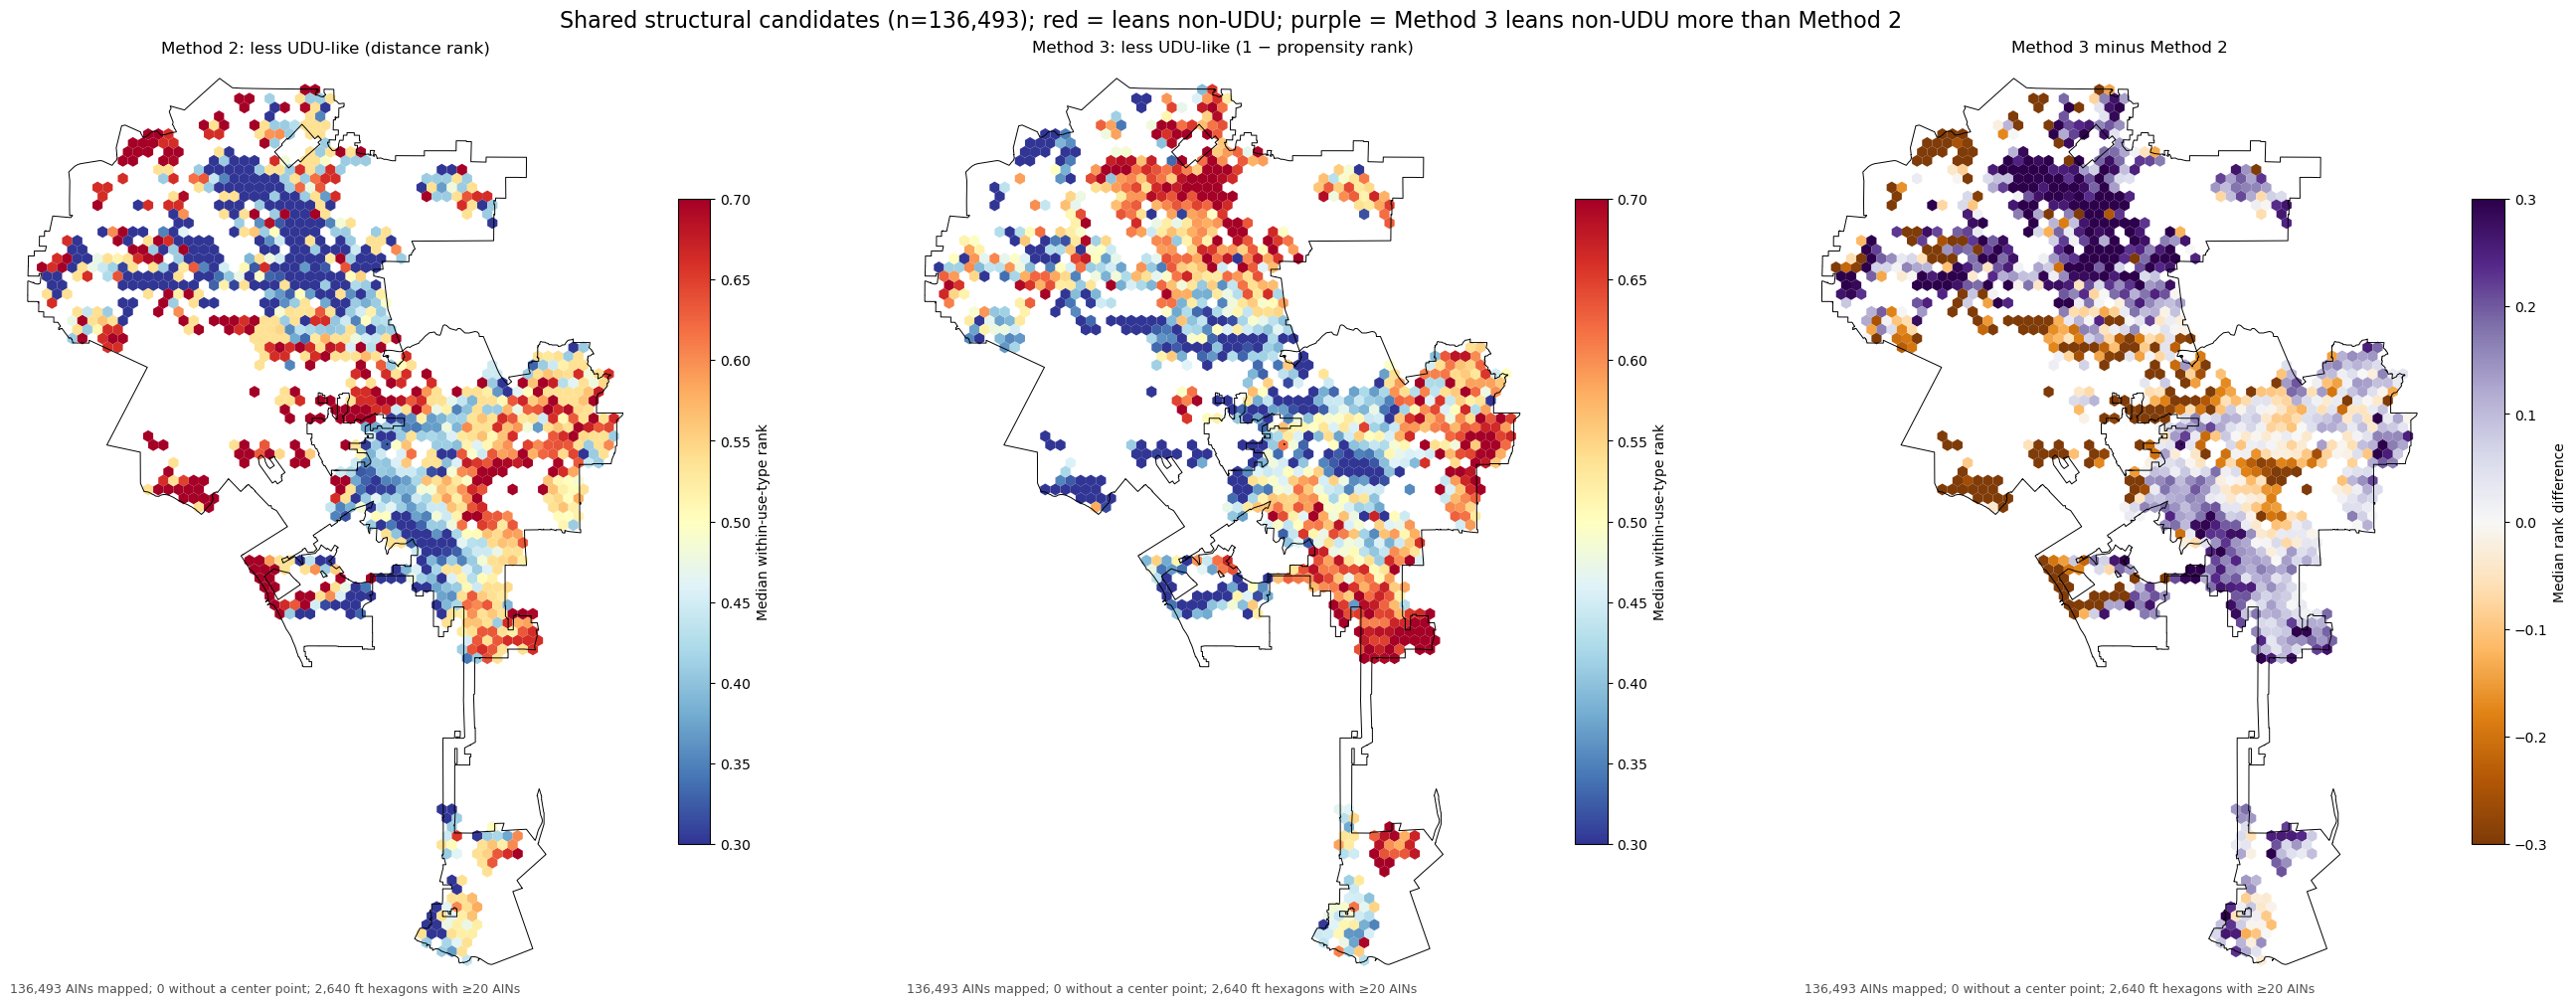

In [5]:
boundary = gpd.read_file(CITY_BOUNDARY).to_crs(AIN_POINT_CRS)
minx, miny, maxx, maxy = boundary.total_bounds
pad = 0.02 * max(maxx - minx, maxy - miny)

def frame_city(ax):
    boundary.boundary.plot(ax=ax, color='k', linewidth=0.7)
    ax.set_xlim(minx - pad, maxx + pad)
    ax.set_ylim(miny - pad, maxy + pad)
    ax.set_aspect('equal')
    ax.set_axis_off()

located['rank_difference'] = located['method3_rank'] - located['method2_rank']
map_points = located[['AIN', 'x', 'y']]
fig, axes = plt.subplots(1, 3, figsize=(27, 10), constrained_layout=True)
for ax, column, cmap, vmin, vmax, title, label in [
    (axes[0], 'method2_rank', 'RdYlBu_r', 0.3, 0.7,
     'Method 2: less UDU-like (distance rank)', 'Median within-use-type rank'),
    (axes[1], 'method3_rank', 'RdYlBu_r', 0.3, 0.7,
     'Method 3: less UDU-like (1 − propensity rank)', 'Median within-use-type rank'),
    (axes[2], 'rank_difference', 'PuOr', -0.3, 0.3,
     'Method 3 minus Method 2', 'Median rank difference'),
]:
    plot_ain_hexbin(
        located, column, points=map_points, ax=ax, hex_width_ft=CELL_FT,
        min_count=MIN_CELL_AINS, cmap=cmap, vmin=vmin, vmax=vmax,
        title=title, colorbar_label=label,
    )
    frame_city(ax)
fig.suptitle(
    f'Shared structural candidates (n={len(located):,}); red = leans non-UDU; '
    'purple = Method 3 leans non-UDU more than Method 2',
    fontsize=16,
)
plt.show()

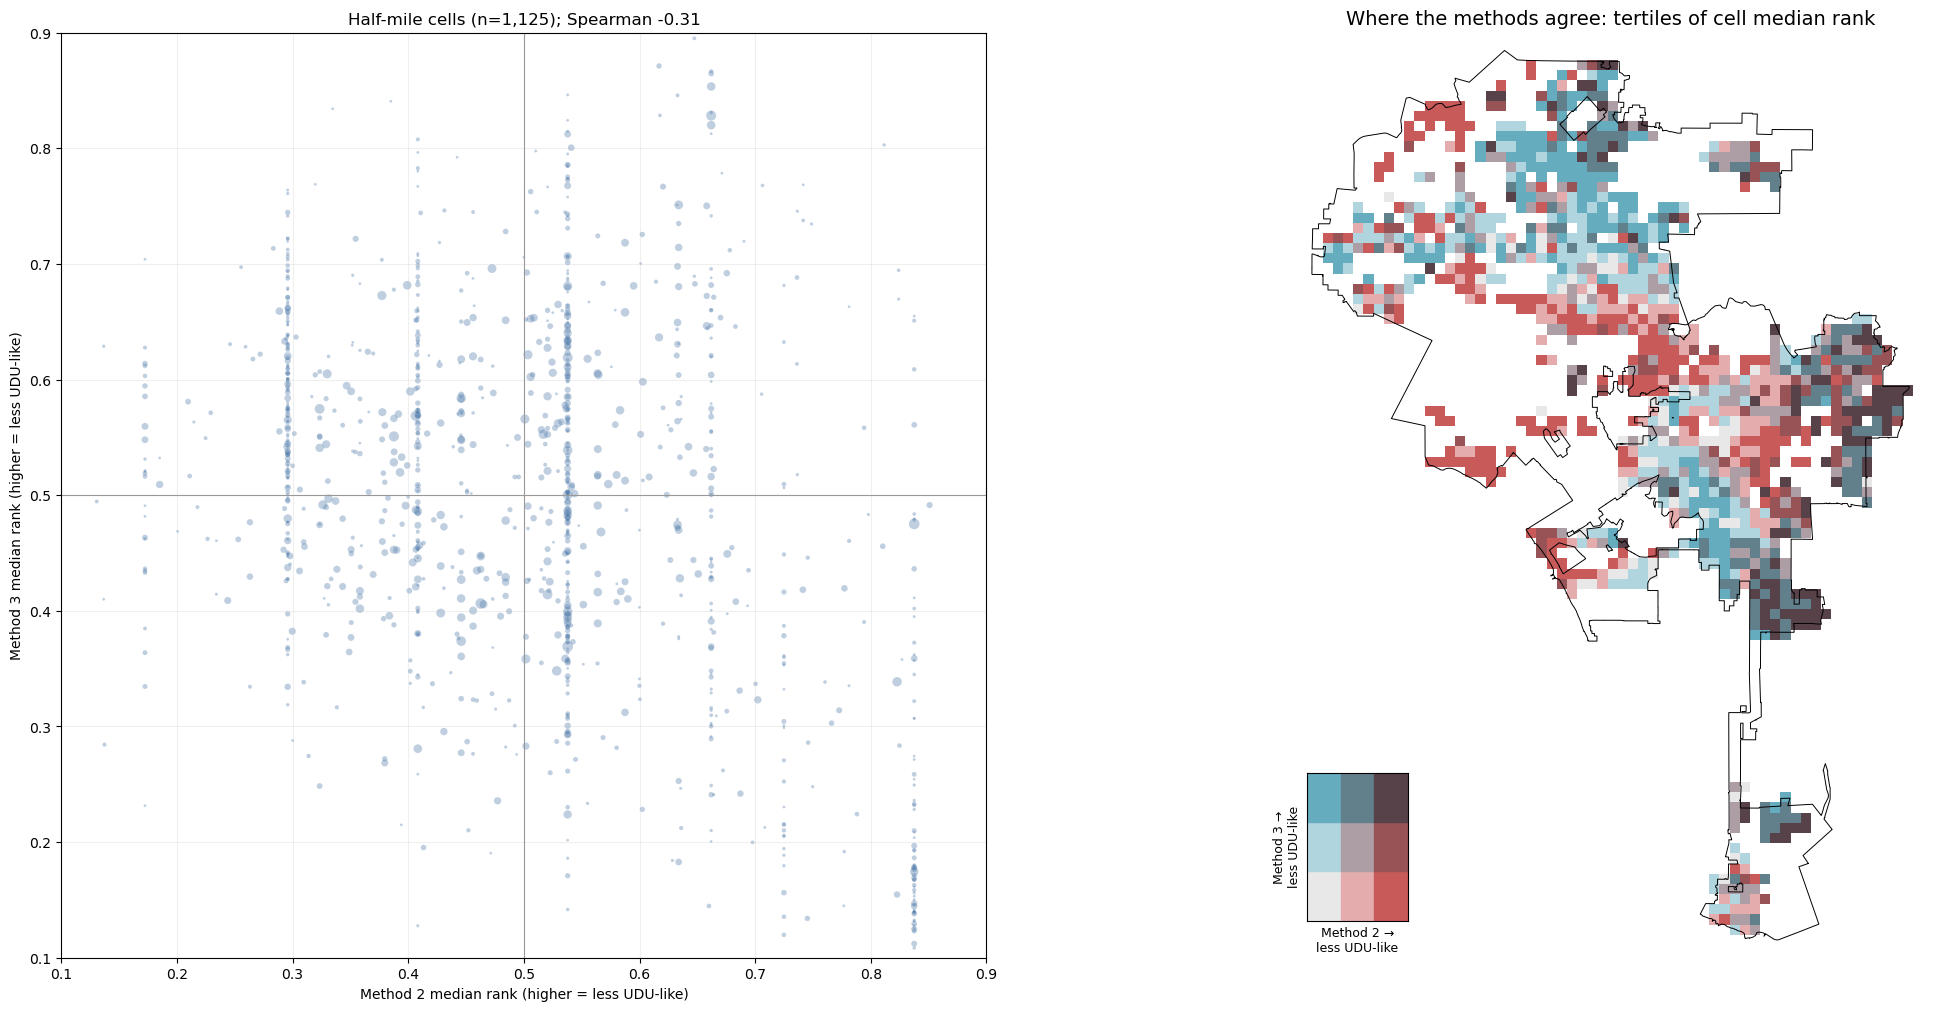

In [6]:
# Bivariate palette: rows are Method 2 tertiles, columns Method 3 tertiles.
BIVARIATE = np.array([
    ['#e8e8e8', '#b0d5df', '#64acbe'],
    ['#e4acac', '#ad9ea5', '#627f8c'],
    ['#c85a5a', '#985356', '#574249'],
])
fig, axes = plt.subplots(
    1, 2, figsize=(22, 10), constrained_layout=True,
    gridspec_kw={'width_ratios': [1, 1.25]},
)
ax = axes[0]
ax.scatter(
    cells['method2'], cells['method3'], s=np.clip(cells['ains'] / 8, 4, 60),
    alpha=0.35, color='#4c78a8', linewidths=0,
)
ax.axhline(0.5, color='#999999', linewidth=0.8)
ax.axvline(0.5, color='#999999', linewidth=0.8)
ax.set(
    xlim=(0.1, 0.9), ylim=(0.1, 0.9), aspect='equal',
    xlabel='Method 2 median rank (higher = less UDU-like)',
    ylabel='Method 3 median rank (higher = less UDU-like)',
    title=f"Half-mile cells (n={len(cells):,}); Spearman {spearman(cells, 'method2', 'method3'):.2f}",
)
ax.grid(alpha=0.2)

ax = axes[1]
squares = [
    [(x * CELL_FT, y * CELL_FT), ((x + 1) * CELL_FT, y * CELL_FT),
     ((x + 1) * CELL_FT, (y + 1) * CELL_FT), (x * CELL_FT, (y + 1) * CELL_FT)]
    for x, y in zip(cells['cell_x'], cells['cell_y'])
]
ax.add_collection(PolyCollection(
    squares, facecolors=BIVARIATE[cells['method2_tertile'], cells['method3_tertile']],
    edgecolors='none',
))
frame_city(ax)
ax.set_title('Where the methods agree: tertiles of cell median rank', fontsize=14)
key = ax.inset_axes([0.02, 0.04, 0.16, 0.16])
for row in range(3):
    for column in range(3):
        key.add_patch(plt.Rectangle((row, column), 1, 1, color=BIVARIATE[row, column]))
key.set(xlim=(0, 3), ylim=(0, 3), xticks=[], yticks=[])
key.set_xlabel('Method 2 →\nless UDU-like', fontsize=9)
key.set_ylabel('Method 3 →\nless UDU-like', fontsize=9)
plt.show()

## What drives the difference?

Land value is Method 3's strongest SHAP feature, and Mahalanobis distance rewards parcels that are unusual in any direction. The table relates each method's rank to the 2016 assessor land value and building area, both ranked within use type. "Land-value extremeness" is the distance of that rank from the median. The last line asks whether the areas still disagree once land value is held fixed.

In [7]:
with sqlite3.connect(MASTER_DB) as connection:
    assessor_2016 = pd.read_sql_query(
        'SELECT AssessorID, roll_landvalue_2016, sqftmain_2016 FROM all_parcel_data',
        connection,
    )
assessor_2016['AIN'] = assessor_2016['AssessorID'].str.replace('-', '', regex=False)
drivers = located.merge(
    assessor_2016[['AIN', 'roll_landvalue_2016', 'sqftmain_2016']],
    on='AIN', how='left', validate='one_to_one',
)
drivers['land_value'] = drivers['roll_landvalue_2016'].where(drivers['roll_landvalue_2016'].gt(0))
drivers['land_value_rank'] = drivers.groupby('SpecificUseType')['land_value'].rank(pct=True)
drivers['building_sqft_rank'] = drivers.groupby('SpecificUseType')['sqftmain_2016'].rank(pct=True)
drivers['land_value_extremeness'] = (drivers['land_value_rank'] - 0.5).abs()

display(pd.DataFrame({
    method: {
        driver: spearman(drivers, f'{method}_rank', driver)
        for driver in ['land_value_rank', 'building_sqft_rank', 'land_value_extremeness']
    }
    for method in ['method2', 'method3']
}).rename(columns={'method2': 'Method 2', 'method3': 'Method 3'}).round(3))

cell_drivers = drivers.groupby(['cell_x', 'cell_y']).agg(
    ains=('AIN', 'size'), method2=('method2_rank', 'median'),
    method3=('method3_rank', 'median'), land=('land_value_rank', 'median'),
)
cell_drivers = cell_drivers.loc[cell_drivers['ains'].ge(MIN_CELL_AINS)]

def residual_ranks(values, control):
    values, control = values.rank().to_numpy(), control.rank().to_numpy()
    return values - np.polyval(np.polyfit(control, values, 1), control)

display(pd.Series({
    'cell Spearman: Method 2 vs median land value': spearman(cell_drivers, 'method2', 'land'),
    'cell Spearman: Method 3 vs median land value': spearman(cell_drivers, 'method3', 'land'),
    'cell Method 2 vs 3, land value held fixed (partial rank correlation)': np.corrcoef(
        residual_ranks(cell_drivers['method2'], cell_drivers['land']),
        residual_ranks(cell_drivers['method3'], cell_drivers['land']),
    )[0, 1],
    'distinct Method 2 percentiles among single-family candidates': shared.loc[
        shared['SpecificUseType'].eq('Single Family Residence'),
        'method2_udu_distance_percentile',
    ].nunique(),
}, name='value').to_frame().round(3))

,Method 2,Method 3
land_value_rank,0.027,-0.550
building_sqft_rank,0.160,-0.453
land_value_extremeness,0.202,0.089


,value
cell Spearman: Method 2 vs median land value,0.221
cell Spearman: Method 3 vs median land value,-0.717
"cell Method 2 vs 3, land value held fixed (partial rank correlation)",-0.223
distinct Method 2 percentiles among single-family candidates,14.000


## All three methods in one table

`all_methods` has one row per AIN scored by any method (an outer join). Each method contributes its final flag, `methodN_potential_nonudu` (the value in its `methodN_output`), followed by its sub-metrics, each with its own score and flag. A flag is missing (`<NA>`) where a method did not score the AIN, which is different from `False`.

| method and sub-metric | columns | score direction and flag rule |
|---|---|---|
| Method 1 residual screen (final) | `method1_residual_sqft`, `method1_residual_score`, `method1_residual_potential_nonudu` | within-use-type rank of \|LARIAC floor area − SQFTmain\|; **low = close agreement**; bottom 2.5% with a positive residual |
| Method 1 ratio screen | `method1_ratio`, `method1_ratio_score`, `method1_ratio_potential_nonudu` | within-use-type rank of LARIAC floor area / SQFTmain; **low = assessor records at least as much area**; bottom 5% |
| Method 2 structural screen | `method2_structural_screen`, `method2_check_*` | each stability check, and whether all passed |
| Method 2 UDU similarity (final) | `method2_distance`, `method2_distance_score`, `method2_udu_like`, `method2_status` | share of known UDUs closer to the UDU profile; **high = less UDU-like**; passes the screen and lies beyond the known-UDU 90th percentile |
| Method 3 tract-matched baseline | `method3_baseline_score`, `method3_baseline_rank`, `method3_baseline_potential_nonudu` | UDU propensity; **high = more UDU-like**; bottom 5% within use type |
| Method 3 regularized | `method3_regularized_*` | as the baseline |
| Method 3 land-value-matched | `method3_landvalue_*`, `method3_landvalue_band_rank` | as the baseline, but flagged in the bottom 5% within use type × land-value band |

`method3_final_model` records which Method 3 model supplies `method3_potential_nonudu`. `methods_flagging` counts the three final flags that are true, and `all_methods_potential_nonudu` is true only where every method scored and flagged the AIN.

In [8]:
METHOD1_COLUMNS = {
    'floor_area_continuous_sqft': 'method1_floor_area_continuous_sqft',
    'raw_residual_sqft': 'method1_residual_sqft',
    'abs_residual_pct_rank_by_use_type': 'method1_residual_score',
    'method1_potential_nonudu': 'method1_residual_potential_nonudu',
    'floor_area_to_sqft_ratio': 'method1_ratio',
    'ratio_pct_rank_by_use_type': 'method1_ratio_score',
    'method1_ratio_potential_nonudu': 'method1_ratio_potential_nonudu',
}
METHOD2_COLUMNS = {
    'SpecificUseType': 'method2_use_type',
    'is_known_udu': 'method2_known_udu',
    'method2_potential_nonudu': 'method2_potential_nonudu',
    'method2_structural_screen': 'method2_structural_screen',
    **{
        column: f'method2_{column}'
        for column in method2_scores.columns if column.startswith('check_')
    },
    'method2_mahalanobis_distance': 'method2_distance',
    'method2_udu_distance_percentile': 'method2_distance_score',
    'method2_udu_like': 'method2_udu_like',
    'method2_status': 'method2_status',
}
METHOD3_COLUMNS = {
    'SpecificUseType': 'method3_use_type',
    'is_known_udu': 'method3_known_udu',
    'method3_landvalue_band': 'LandValueBand',
    'method3_potential_nonudu': 'method3_potential_nonudu',
    'method3_final_model': 'method3_final_model',
    **{
        f'method3_{model}_{source}': f'method3_{model}_{target}'
        for model in ['baseline', 'regularized', 'landvalue']
        for source, target in [
            ('udu_score', 'score'),
            ('score_pct_rank_by_use_type', 'rank'),
            ('potential_nonudu', 'potential_nonudu'),
        ]
    },
    'method3_landvalue_score_pct_rank_by_band': 'method3_landvalue_band_rank',
}
FINAL_FLAGS = [
    'method1_potential_nonudu', 'method2_potential_nonudu', 'method3_potential_nonudu',
]

all_methods = (
    method3_scores[['AIN', *METHOD3_COLUMNS]].rename(columns=METHOD3_COLUMNS)
    .merge(
        method2_scores[['AIN', *METHOD2_COLUMNS]].rename(columns=METHOD2_COLUMNS),
        on='AIN', how='outer', validate='one_to_one',
    )
    .merge(
        method1_scores[['AIN', *METHOD1_COLUMNS]].rename(columns=METHOD1_COLUMNS),
        on='AIN', how='outer', validate='one_to_one',
    )
)
# Method 1 publishes its residual screen as its final flag (method1_output).
all_methods['method1_potential_nonudu'] = all_methods['method1_residual_potential_nonudu']
all_methods['UseType'] = all_methods['method3_use_type'].fillna(all_methods['method2_use_type'])
all_methods['KnownUDU'] = all_methods['method3_known_udu'].fillna(all_methods['method2_known_udu'])
all_methods['LandValueBand'] = all_methods['LandValueBand'].astype('Int64')
boolean_columns = [
    column for column in all_methods.columns
    if column.endswith(('potential_nonudu', 'structural_screen', 'udu_like'))
    or column.startswith('method2_check_') or column == 'KnownUDU'
]
all_methods[boolean_columns] = all_methods[boolean_columns].astype('boolean')
all_methods['methods_scoring'] = all_methods[FINAL_FLAGS].notna().sum(axis=1)
all_methods['methods_flagging'] = all_methods[FINAL_FLAGS].fillna(False).sum(axis=1)
all_methods['all_methods_potential_nonudu'] = all_methods['methods_flagging'].eq(len(FINAL_FLAGS))

identity = {'method2_use_type', 'method2_known_udu', 'method3_use_type', 'method3_known_udu', 'LandValueBand'}
all_methods = all_methods[[
    'AIN', 'UseType', 'LandValueBand', 'KnownUDU',
    'method1_potential_nonudu', *METHOD1_COLUMNS.values(),
    *[column for column in METHOD2_COLUMNS.values() if column not in identity],
    *[column for column in METHOD3_COLUMNS.values() if column not in identity],
    'methods_scoring', 'methods_flagging', 'all_methods_potential_nonudu',
]].sort_values('AIN').reset_index(drop=True)

with pd.option_context('display.max_columns', None):
    display(all_methods.head(10))
    display(all_methods.loc[all_methods['all_methods_potential_nonudu']].head(10))

,AIN,UseType,LandValueBand,KnownUDU,method1_potential_nonudu,method1_floor_area_continuous_sqft,method1_residual_sqft,method1_residual_score,method1_residual_potential_nonudu,method1_ratio,method1_ratio_score,method1_ratio_potential_nonudu,method2_potential_nonudu,method2_structural_screen,method2_check_eligible_snapshot,method2_check_no_structural_change,method2_check_assessor_stable,method2_check_lot_size,method2_check_building_count,method2_check_floor_area_ratio,method2_distance,method2_distance_score,method2_udu_like,method2_status,method3_potential_nonudu,method3_final_model,method3_baseline_score,method3_baseline_rank,method3_baseline_potential_nonudu,method3_regularized_score,method3_regularized_rank,method3_regularized_potential_nonudu,method3_landvalue_score,method3_landvalue_rank,method3_landvalue_potential_nonudu,method3_landvalue_band_rank,methods_scoring,methods_flagging,all_methods_potential_nonudu
0,2004001003,Single Family Residence,8,False,False,9127.40,7037.40,0.955968,False,4.367177,0.960260,False,False,False,True,True,True,True,False,False,NaN,NaN,False,not_structurally_stable,False,baseline,0.084885,0.154909,False,0.181972,0.262135,False,0.027296,0.009359,True,0.013003,3,0,False
1,2004001004,Single Family Residence,6,False,False,7448.74,4969.74,0.874527,False,3.004736,0.670730,False,False,False,True,True,True,True,True,False,NaN,NaN,False,not_structurally_stable,False,baseline,0.429744,0.944081,False,0.530635,0.953837,False,0.263454,0.860817,False,0.851504,3,0,False
2,2004001005,Single Family Residence,3,False,False,7991.85,5934.85,0.925909,False,3.885197,0.920522,False,False,False,True,True,True,True,True,False,NaN,NaN,False,not_structurally_stable,False,baseline,0.348032,0.863445,False,0.443215,0.868923,False,0.202676,0.745349,False,0.769122,3,0,False
3,2004001008,Single Family Residence,3,False,False,9220.63,6797.63,0.950978,False,3.805460,0.909883,False,False,False,True,True,True,False,False,False,NaN,NaN,False,not_structurally_stable,False,baseline,0.080636,0.137957,False,0.176041,0.243953,False,0.039397,0.040167,True,0.034668,3,0,False
4,2004001009,Single Family Residence,2,False,False,8626.21,6400.21,0.940910,False,3.875207,0.919248,False,False,False,True,False,True,False,True,False,NaN,NaN,False,not_structurally_stable,False,baseline,0.291334,0.775950,False,0.453499,0.881885,False,0.159642,0.613202,False,0.630358,3,0,False
5,2004001010,Single Family Residence,3,False,False,7471.99,5048.99,0.880203,False,3.083776,0.707692,False,False,False,True,True,True,False,True,False,NaN,NaN,False,not_structurally_stable,False,baseline,0.273641,0.742846,False,0.426229,0.845530,False,0.204126,0.748963,False,0.772953,3,0,False
6,2004001011,Single Family Residence,2,False,False,8014.51,5591.51,0.911296,False,3.307681,0.795467,False,False,False,True,True,True,False,True,False,NaN,NaN,False,not_structurally_stable,False,baseline,0.266565,0.728561,False,0.416323,0.830681,False,0.177153,0.673432,False,0.693192,3,0,False
7,2004001012,Single Family Residence,6,False,False,5472.95,3246.95,0.631082,False,2.458648,0.355771,False,False,False,True,True,True,False,True,True,NaN,NaN,False,not_structurally_stable,False,baseline,0.202866,0.575869,False,0.345739,0.702958,False,0.087813,0.280238,False,0.283293,3,0,False
8,2004001013,Single Family Residence,4,False,False,9165.87,6814.87,0.951333,False,3.898711,0.922221,False,False,False,True,True,True,False,True,False,NaN,NaN,False,not_structurally_stable,False,baseline,0.325463,0.831790,False,0.428330,0.848587,False,0.169585,0.648432,False,0.639809,3,0,False
9,2004001014,Single Family Residence,5,False,False,7843.78,5420.78,0.902794,False,3.237218,0.770860,False,False,False,True,True,True,False,True,False,NaN,NaN,False,not_structurally_stable,False,baseline,0.301953,0.794181,False,0.473654,0.905207,False,0.180864,0.684929,False,0.672154,3,0,False


,AIN,UseType,LandValueBand,KnownUDU,method1_potential_nonudu,method1_floor_area_continuous_sqft,method1_residual_sqft,method1_residual_score,method1_residual_potential_nonudu,method1_ratio,method1_ratio_score,method1_ratio_potential_nonudu,method2_potential_nonudu,method2_structural_screen,method2_check_eligible_snapshot,method2_check_no_structural_change,method2_check_assessor_stable,method2_check_lot_size,method2_check_building_count,method2_check_floor_area_ratio,method2_distance,method2_distance_score,method2_udu_like,method2_status,method3_potential_nonudu,method3_final_model,method3_baseline_score,method3_baseline_rank,method3_baseline_potential_nonudu,method3_regularized_score,method3_regularized_rank,method3_regularized_potential_nonudu,method3_landvalue_score,method3_landvalue_rank,method3_landvalue_potential_nonudu,method3_landvalue_band_rank,methods_scoring,methods_flagging,all_methods_potential_nonudu
99370,2301002044,Single Family Residence,2,False,True,565.02,53.02,0.001227,True,1.103555,0.011018,True,True,True,True,True,True,True,True,True,8.865891,1.000000,False,potential_nonudu,True,baseline,0.041329,0.017909,True,0.094126,0.039053,True,0.086627,0.273811,False,0.261877,3,3,True
115486,2337014015,"Double, Duplex, or Two Units",1,False,True,1697.08,187.08,0.006508,True,1.123894,0.016586,True,True,True,True,True,True,True,True,True,5.683492,0.955556,False,potential_nonudu,True,baseline,0.047018,0.021278,True,0.083878,0.021255,True,0.124349,0.185647,False,0.253212,3,3,True
131263,2378009039,"Double, Duplex, or Two Units",2,False,True,1473.27,486.27,0.023257,True,1.492675,0.081459,False,True,True,True,True,True,True,True,True,4.900836,0.900000,False,potential_nonudu,True,baseline,0.042034,0.014629,True,0.076536,0.014512,True,0.061243,0.028884,True,0.039234,3,3,True
146595,2505011906,"Double, Duplex, or Two Units",0,False,True,1926.95,262.95,0.010357,True,1.158023,0.018872,True,True,True,True,True,True,True,True,True,5.098743,0.933333,False,potential_nonudu,True,baseline,0.023729,0.001237,True,0.049703,0.001797,True,0.023493,0.000443,False,0.088889,3,3,True
160583,2546004005,Single Family Residence,1,False,True,479.32,99.32,0.002384,True,1.261368,0.015906,True,True,True,True,True,True,True,True,True,8.052941,0.923077,False,potential_nonudu,True,baseline,0.034595,0.008688,True,0.088946,0.031228,True,0.030511,0.015404,True,0.011982,3,3,True
169941,2569001022,Single Family Residence,4,False,True,422.03,122.03,0.002894,True,1.406767,0.023681,True,True,True,True,True,True,True,True,True,7.948065,0.923077,False,potential_nonudu,True,baseline,0.053103,0.043946,True,0.124789,0.099612,False,0.037584,0.034069,True,0.031394,3,3,True
243129,2784005053,Five or More Units or Apartments (Any Combinat...,1,False,True,1262.48,686.48,0.018108,True,2.191806,0.887174,False,True,True,True,True,True,True,True,True,9.279841,1.000000,False,potential_nonudu,True,baseline,0.039388,0.004930,True,0.079952,0.006436,True,0.036807,0.002328,True,0.005493,3,3,True
249083,4004007004,Five or More Units or Apartments (Any Combinat...,1,False,True,2175.72,541.72,0.013042,True,1.331530,0.123336,False,True,True,True,True,True,True,True,True,4.775641,0.911602,False,potential_nonudu,True,baseline,0.060930,0.024581,True,0.128346,0.042727,True,0.055258,0.014174,True,0.030896,3,3,True
250656,4006005021,Three Units (Any Combination),3,False,True,2163.10,227.10,0.005714,True,1.117304,0.013480,True,True,True,True,True,True,True,True,True,4.877500,0.905405,False,potential_nonudu,True,baseline,0.065518,0.041251,True,0.134427,0.076495,False,0.110206,0.109760,False,0.115187,3,3,True
267257,4225006012,Five or More Units or Apartments (Any Combinat...,5,False,True,2428.02,460.02,0.011159,True,1.233750,0.065348,False,True,True,True,True,True,True,True,True,6.537636,0.988950,False,potential_nonudu,True,baseline,0.054558,0.017700,True,0.118841,0.032832,True,0.084839,0.053271,True,0.048044,3,3,True


In [9]:
import itertools

in_all = all_methods.loc[all_methods['methods_scoring'].eq(len(FINAL_FLAGS))]
final_all = in_all['all_methods_potential_nonudu']
final_shares = in_all[FINAL_FLAGS].astype(float).mean()
display(pd.Series({
    'AINs scored by any method': len(all_methods),
    'AINs scored by all three methods': len(in_all),
    'AINs scored by one or two methods only': int(all_methods['methods_scoring'].lt(3).sum()),
    **{f'{flag} share': final_shares[flag] for flag in FINAL_FLAGS},
    'AINs flagged by all three (final flags)': int(final_all.sum()),
    'share flagged by all three (of AINs scored by all three)': final_all.mean(),
    'share flagged by all three (of all AINs)': final_all.sum() / len(all_methods),
    'share expected if the flags were independent': final_shares.prod(),
}, name='final flags').to_frame())
display(
    in_all['methods_flagging'].value_counts().sort_index()
    .rename('AINs').to_frame()
    .assign(share=lambda frame: frame['AINs'] / frame['AINs'].sum())
    .rename_axis('final flags true')
)

# Every combination of one sub-metric flag per method.
SUBMETRIC_FLAGS = {
    'Method 1': {
        'residual': 'method1_residual_potential_nonudu',
        'ratio': 'method1_ratio_potential_nonudu',
    },
    'Method 2': {'similarity': 'method2_potential_nonudu'},
    'Method 3': {
        'baseline': 'method3_baseline_potential_nonudu',
        'regularized': 'method3_regularized_potential_nonudu',
        'land value': 'method3_landvalue_potential_nonudu',
    },
}
combinations = []
for labels in itertools.product(*(options.keys() for options in SUBMETRIC_FLAGS.values())):
    columns = [SUBMETRIC_FLAGS[method][label] for method, label in zip(SUBMETRIC_FLAGS, labels)]
    flags = in_all[columns].fillna(False)
    all_true = flags.all(axis=1)
    combinations.append({
        **dict(zip(SUBMETRIC_FLAGS, labels)),
        'AINs flagged by all three': int(all_true.sum()),
        'share of AINs scored by all three': all_true.mean(),
        'expected if independent': flags.astype(float).mean().prod(),
    })
display(pd.DataFrame(combinations).sort_values('AINs flagged by all three', ascending=False))
display(
    in_all.groupby('UseType').agg(
        ains=('AIN', 'size'),
        flagged_by_all_three=('all_methods_potential_nonudu', 'sum'),
    )
    .assign(share=lambda frame: frame['flagged_by_all_three'] / frame['ains'])
    .sort_values('ains', ascending=False)
)

,final flags
AINs scored by any method,535193.000000
AINs scored by all three methods,535131.000000
AINs scored by one or two methods only,62.000000
method1_potential_nonudu share,0.020559
method2_potential_nonudu share,0.017745
method3_potential_nonudu share,0.049980
AINs flagged by all three (final flags),98.000000
share flagged by all three (of AINs scored by all three),0.000183
share flagged by all three (of all AINs),0.000183
share expected if the flags were independent,0.000018


,AINs,share
final flags true,,
0,490050,0.915757
1,43016,0.080384
2,1967,0.003676
3,98,0.000183


,Method 1,Method 2,Method 3,AINs flagged by all three,share of AINs scored by all three,expected if independent
3,ratio,similarity,baseline,139,0.000260,0.000044
5,ratio,similarity,land value,132,0.000247,0.000044
4,ratio,similarity,regularized,114,0.000213,0.000044
2,residual,similarity,land value,103,0.000192,0.000018
0,residual,similarity,baseline,98,0.000183,0.000018
1,residual,similarity,regularized,74,0.000138,0.000018


,ains,flagged_by_all_three,share
UseType,,,
Single Family Residence,430801,32,0.000074
"Double, Duplex, or Two Units",42861,16,0.000373
Five or More Units or Apartments (Any Combination),29209,41,0.001404
Three Units (Any Combination),13648,6,0.00044
Four Units (Any Combination),13396,2,0.000149
Store Combination,5216,1,0.000192


In [10]:
# Combined AIN-level table; see notebooks/methods/DATA_DICTIONARY.md for every column.
ALL_METHODS_CSV = PROJECT_ROOT / 'data/03_processed/method_comparison/all_methods_potential_nonudu_2017.csv'
ALL_METHODS_CSV.parent.mkdir(parents=True, exist_ok=True)
all_methods.to_csv(ALL_METHODS_CSV, index=False, float_format='%.6g')
print(
    f'Saved {len(all_methods):,} rows x {all_methods.shape[1]} columns to {ALL_METHODS_CSV} '
    f'({ALL_METHODS_CSV.stat().st_size / 1e6:.0f} MB)'
)

Saved 535,193 rows x 39 columns to /Users/adamswietek/Documents/NDSC_HiddenHousing/data/03_processed/method_comparison/all_methods_potential_nonudu_2017.csv (153 MB)


## Findings

These numbers come from the run of 23 October 2026 on the 36 currently completed city tiles. All three methods use continuous-height floor-area inputs, and the tract-matched baseline is the final Method 3 model. Rerun notebooks 01–03 and then this notebook after the remaining city tile completes.

- **Methods 2 and 3 barely agree on individual parcels.** Across 136,493 shared structural candidates the rank correlation was 0.019. Within use type it was weakly positive for multi-unit and store-combination parcels (0.159–0.233) and negative for single-family homes (−0.222).
- **Their flags overlap slightly more than chance, but little in absolute terms.** 718 parcels were flagged by both, 1.80 times the independent rate, out of 9,496 Method 2 and 26,746 Method 3 flags. Another 20,999 Method 3 flags fail Method 2's structural screen.
- **They disagree about areas, often in opposite directions.** The correlation of half-mile cell medians was −0.311 (−0.351 for the regularized Method 3). Only 3 of the 112 top-decile cells were shared, against about 11 by chance.
- **Land value explains much of it.** Method 3's rank correlated −0.55 with land-value rank at the parcel level and −0.72 at the cell level, so its least-UDU-like areas are largely the low-land-value areas. Method 3 learns only within-tract contrasts, so its between-area pattern is an extrapolation. Method 2's rank tracked building size (0.16) and land-value extremeness (0.20), consistent with a distance that flags unusual parcels in any direction. With land value held fixed, the areas still disagreed (−0.22).
- **Method 2's single-family score is coarse.** It takes only as many values as there are known single-family UDUs (14), so its area medians fall into bands.
- **Almost no parcel is flagged by all three methods.** Of 535,131 AINs scored by all three, 98 (0.018%) carry all three final flags. That is about 10 times what independent flags would give (0.0018%), but far too few to act as a combined screen. Across all AINs, 1,967 carry exactly two final flags and 43,016 carry one. Across the six sub-metric combinations the all-three count ranges from 74 to 139; Method 1's continuous ratio screen with the Method 3 baseline gives the most. Single-family parcels supply 32 of the 98, and five-or-more-unit parcels supply 41.

Neither map reads directly as where UDUs are absent, and the methods mostly flag different parcels. Method 3's regional pattern should be read within areas or controlled for land value before it is combined with the others.